# How good is the PanGenie side of the panel?

The 231-founder panel is **two panels merged**: **78 founders genotyped from their own
long-read assemblies** (the cactus/minigraph side) and **153 genotyped from short reads by
PanGenie** against the 135-assembly 1001G+ graph. Every allele frequency kMate produces is a
projection through this panel, so this side's quality propagates into everything downstream.

Two separate questions, one figure each:

1. **Coverage** — of the variation the 78 assemblies reveal, **how much can PanGenie call from
   short reads in the other 153?** Where it calls nothing, the merge fills those founders with
   `./.` and the record reaches the analysis genotyped in only the 78. kMate handles that
   correctly (`AF = (h @ var_pa) / (h @ var_called)` drops uncalled founders from the
   denominator rather than counting them as reference), so the cost is **precision, not bias**.
2. **Accuracy** — where it *does* call, how often is it right? This is the failure mode that
   should worry us more, because nothing downstream flags it.

### Two metrics, and only the second is informative

| | what it counts |
|---|---|
| **GC** — genotype concordance | every record where the call matches truth, **including the vast majority where both are homozygous reference**. Most of the genome is reference for most founders, so GC sits near 99% almost regardless of quality — it largely measures how invariant the genome is. |
| **nRD** — non-reference discordance | only records where **truth or the call is non-reference**, and asks how often they disagree. For a rare candidate allele — which is what a GEA hit usually is — this is the only one of the two that means anything. |

**Read nRD. GC is reported alongside only to show why it is uninformative.**

### The final panel set

Ecotypes **5772 and 9947** are excluded from the accuracy figures. Their assemblies were
dropped as duplicate-pair members (`data/exclude_list.txt` → assemblies 100852, 101003) and
they are PanGenie-substituted in production, so scoring them against an assembly the project
decided not to trust would charge PanGenie for a labelling problem. That leaves **73** of the
75 leave-one-out founders.

In [1]:
import os, glob, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False})
def _root(d=None):
    d = os.path.abspath(d or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.isdir(os.path.join(d, "panel", "arch3")) and os.path.isdir(os.path.join(d, "analysis")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no kmate root above " + os.getcwd())
P = _root()
QC = f"{P}/analysis/panel_qc"
PLOTS = f"{P}/analysis/grenenet_selection/notebooks/plots/pangenie_accuracy"
os.makedirs(PLOTS, exist_ok=True)

GREEN = ["#2f6b4f", "#4e9e75", "#8cc7a5", "#cfe8da"]
GREY, ACCENT = "#9a9a9a", "#b4553f"
DROPPED = {5772, 9947}                       # assemblies excluded from the final panel
CLS = ["SNP", "small_indel", "small_sv", "medium_sv", "large_sv"]
CLSLAB = {"SNP": "SNP", "small_indel": "small indel", "small_sv": "small SV\n50-500 bp",
          "medium_sv": "medium SV\n0.5-5 kb", "large_sv": "large SV\n>5 kb"}
STAGES = ["raw", "het", "gq"]
SLAB = {"raw": "raw", "het": "+ het masked", "gq": "+ GQ>=20"}

def panel(ax, letter, note="", y=1.02):
    ax.annotate(letter, (0, y), xycoords="axes fraction", fontweight="bold", fontsize=11,
                va="bottom", ha="left")
    if note:
        ax.annotate(note, (0.075, y), xycoords="axes fraction", fontsize=8.5,
                    va="bottom", ha="left", color="#444")

CALL = pd.read_csv(f"{QC}/pangenie_accuracy/callability_78_vs_153.csv", index_col=0).reindex(CLS)
Q = pd.read_csv(f"{QC}/pangenie_accuracy/loo_qc_stages.csv"); Q["acc"] = Q.acc.astype(int)
G = pd.read_csv(f"{QC}/pangenie_accuracy/loo_qc_stages_grenenet.csv"); G["acc"] = G.acc.astype(int)
Qf, Gf = Q[~Q.acc.isin(DROPPED)], G[~G.acc.isin(DROPPED)]
R = pd.read_csv(f"{QC}/pg_dropout/pg_dropout_regions.csv")
print(f"LOO founders {Q.acc.nunique()} -> {Qf.acc.nunique()} after excluding {sorted(DROPPED)}")

LOO founders 75 -> 73 after excluding [5772, 9947]


## 1 · Coverage — how much of the 78-founder variation can PanGenie see?

Every record that at least one of the 78 assembly founders carries a genotype for, asked of
the 153 short-read founders: **is it callable at all** (≥1 of the 153 genotyped), and **what
share of the 153** got a genotype. Both come straight from the production panel's
`var_called` matrix, so this is the panel as the analysis uses it.

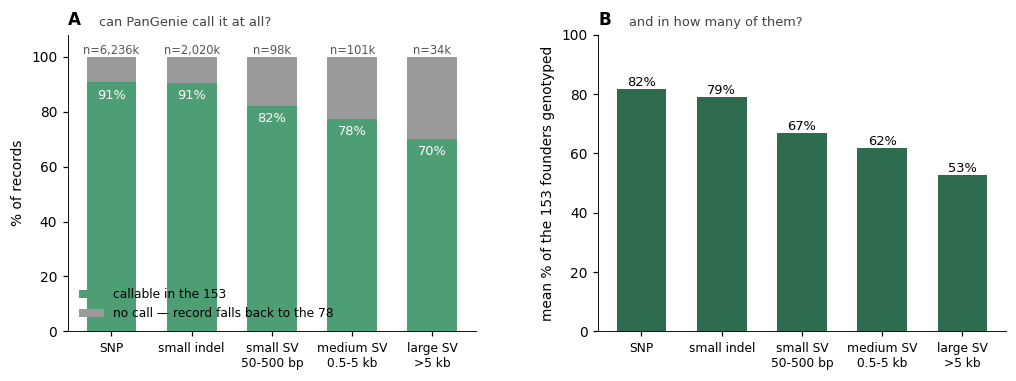

             n_records  pct_callable  mean_callrate
cls                                                
SNP          6236215.0         90.67          81.80
small_indel  2019857.0         90.58          79.14
small_sv       97734.0         81.98          66.94
medium_sv     100854.0         77.50          61.83
large_sv       33891.0         70.07          52.84


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw=dict(wspace=0.3))
xx = np.arange(len(CLS))
ax[0].bar(xx, CALL.pct_callable, 0.62, color=GREEN[1], label="callable in the 153")
ax[0].bar(xx, 100 - CALL.pct_callable, 0.62, bottom=CALL.pct_callable, color=GREY,
          label="no call — record falls back to the 78")
for i, (v, n) in enumerate(zip(CALL.pct_callable, CALL.n_records)):
    ax[0].annotate(f"{v:.0f}%", (i, v), ha="center", va="top", fontsize=8.5,
                   color="white", xytext=(0, -4), textcoords="offset points")
    ax[0].annotate(f"n={n/1e3:,.0f}k", (i, 101), ha="center", fontsize=7.5, color="#555")
ax[0].set_xticks(xx); ax[0].set_xticklabels([CLSLAB[c] for c in CLS], fontsize=8)
ax[0].set_ylim(0, 108); ax[0].set_ylabel("% of records")
ax[0].legend(frameon=False, fontsize=8, loc="lower left")
panel(ax[0], "A", "can PanGenie call it at all?")

ax[1].bar(xx, CALL.mean_callrate, 0.62, color=GREEN[0])
for i, v in enumerate(CALL.mean_callrate):
    ax[1].annotate(f"{v:.0f}%", (i, v), ha="center", va="bottom", fontsize=8.5)
ax[1].set_xticks(xx); ax[1].set_xticklabels([CLSLAB[c] for c in CLS], fontsize=8)
ax[1].set_ylim(0, 100); ax[1].set_ylabel("mean % of the 153 founders genotyped")
panel(ax[1], "B", "and in how many of them?")
plt.savefig(f"{PLOTS}/coverage.png", dpi=150, bbox_inches="tight"); plt.show()
print(CALL.round(2).to_string())

**Reading it.** Of the **8.49 M** records the 78 assemblies reveal, PanGenie calls
**90.3%** in at least one of the 153, at a mean call rate of **80.6%**. Coverage falls
steadily with variant size: **90.7% → 70.1% callable** from SNPs to large SVs, and
**81.8% → 52.8%** mean call rate. So for a >5 kb SV the typical record is genotyped in only
about half the short-read panel.

Genome-wide this concentrates in **131 regions totalling 3.11 Mb (2.60% of the genome,
445 genes)** where PanGenie emits nothing at all — median 10 kb, largest 90 kb, **80% of it in
the chromosome arms rather than centromeres**, and TE-dense (median 5 TEs per 10 kb bin vs 1
elsewhere), which is the mechanism: PanGenie needs unique *k*-mers, and a bubble full of long
TE alleles offers none. FLC is one of these holes.

## 2 · Accuracy — one figure, both yardsticks, all three QC stages

Leave-one-out: each founder re-genotyped with **itself removed from the panel**, so its own
assembly is not available to the genotyper, then scored against truth.

The harness (`loo_concordance.py`) scores the **raw** PanGenie output, but production filters
twice before a genotype reaches an analysis (`qc_pg_v4_filter.sh`,
`build_v3qc_v3_phase_a.sh`): **het → missing** (*A. thaliana* ecotypes are inbred, so a
heterozygous call is an error) and **GQ ≥ 20**. The first matters enormously for this
comparison, because an assembly is homozygous by construction — so every het call is charged
as an error in the raw numbers even though production never sees it.

The last group is the **old GrENE-Net SNP panel** — a completely independent short-read
genotyping of the same accessions — as a check on the assembly-based estimate. It covers SNPs
only, so it is directly comparable to the first group and to nothing else.

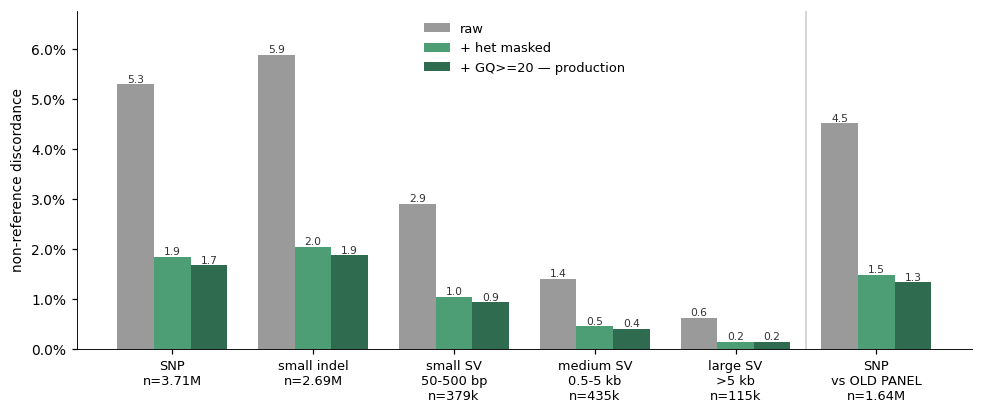

median non-reference discordance, % — 73 founders

                  raw  + het masked  + GQ>=20          n
size_class                                              
SNP              5.29          1.85      1.68  3,706,200
small_indel      5.88          2.05      1.88  2,690,353
small_sv         2.91          1.04      0.94    378,534
medium_sv        1.41          0.46      0.41    434,545
large_sv         0.63          0.15      0.15    114,694
SNP (old panel)  4.51          1.49      1.33  1,640,475

for contrast, genotype concordance (the uninformative metric):
             GC_raw  GC_het  GC_gq
size_class                        
SNP           99.47   99.82  99.84
small_indel   98.41   99.43  99.49
small_sv      97.89   99.24  99.34
medium_sv     98.76   99.59  99.64
large_sv      99.42   99.86  99.86


In [3]:
m = Qf.groupby("size_class")[[f"nRD_{s}" for s in STAGES]].median().reindex(CLS)
n_med = Qf.groupby("size_class")["n_raw"].median().reindex(CLS)
g = Gf.groupby("stage")[["nRD", "n"]].median().reindex(STAGES)

vals = {s: list(m[f"nRD_{s}"].values) + [g.loc[s, "nRD"]] for s in STAGES}
ns = list(n_med.values) + [g.loc["raw", "n"]]
def nfmt(n):
    return f"{n/1e6:.2f}M" if n > 1e6 else f"{n/1e3:.0f}k"
labels = [f"{CLSLAB[c]}\nn={nfmt(n)}" for c, n in zip(CLS, ns)] + [f"SNP\nvs OLD PANEL\nn={nfmt(ns[-1])}"]
fig, ax = plt.subplots(figsize=(10.5, 4))
xx = np.arange(len(labels)); w = 0.26
for i, s in enumerate(STAGES):
    b = ax.bar(xx + (i-1)*w, vals[s], w, color=[GREY, GREEN[1], GREEN[0]][i],
               label=SLAB[s] + (" — production" if s == "gq" else ""))
    for x, v in zip(xx + (i-1)*w, vals[s]):
        ax.annotate(f"{100*v:.1f}", (x, v), ha="center", va="bottom", fontsize=7, color="#333")
ax.axvline(len(CLS) - 0.5, color="#ccc", lw=1)
ax.set_xticks(xx); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel("non-reference discordance"); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, max(vals["raw"]) * 1.15)
ax.legend(frameon=False, fontsize=8.5)
panel(ax, "", "")
plt.savefig(f"{PLOTS}/accuracy.png", dpi=150, bbox_inches="tight"); plt.show()

T = (100*m).round(2); T.columns = [SLAB[s] for s in STAGES]
T.loc["SNP (old panel)"] = (100*g.nRD).round(2).values
T["n"] = [f"{v:,.0f}" for v in ns]
print("median non-reference discordance, % — 73 founders\n"); print(T.to_string())
print("\nfor contrast, genotype concordance (the uninformative metric):")
print((100*Qf.groupby("size_class")[[f"GC_{s}" for s in STAGES]].median().reindex(CLS)).round(2).to_string())

**Reading it.**

- **Production is the dark bar, not the grey one.** QC roughly **thirds** the error:
  SNP 5.3% → **1.7%**, small indel 5.9% → **1.9%**, small SV 2.9% → **0.94%**,
  medium SV 1.4% → **0.41%**, large SV 0.63% → **0.15%**. Nearly all of the gain is the het
  mask, which is expected — against a homozygous assembly a het call cannot be right.
- **PanGenie is more accurate on big variants than on SNPs**, by an order of magnitude at the
  top end. A long indel carries many more discriminating *k*-mers than a single base, so the
  graph genotyper is strongest exactly where short-read calling is usually weakest. That is
  the opposite of what the FLC dropout invites you to assume, and it is the main reassurance
  here.
- **The two yardsticks agree.** The old GrENE-Net panel — different technology, different
  pipeline, an entirely independent truth — gives SNP nRD **4.5% → 1.5% → 1.33%** against
  **5.3% → 1.9% → 1.68%** from the assemblies. Two independent references landing within
  0.35 points of each other is the strongest single statement in this notebook.
- GC, printed below the figure, runs 99.5–99.9% everywhere and separates none of this — which
  is the point of reading nRD instead.

Two caveats that travel with the numbers: the GrENE-Net panel is **Beagle-imputed**, so it is
an independent *genotyping* rather than an independent *calling* at every site; and the
leave-one-out founders all **have** assemblies, so their reads were good enough to assemble —
they are not a random sample of the 153, and real accuracy there is plausibly a little worse.

## 3 · Per-founder spread — and why the worst ones are not PanGenie's fault

**Each dot is one founder** (an ecotype), not a variant: the same 73 accessions, each scored
on its own ~7.3 M records. The median is what the previous figure reports; this shows how much
founders differ, which is a property of each sample's read data as much as of the method.

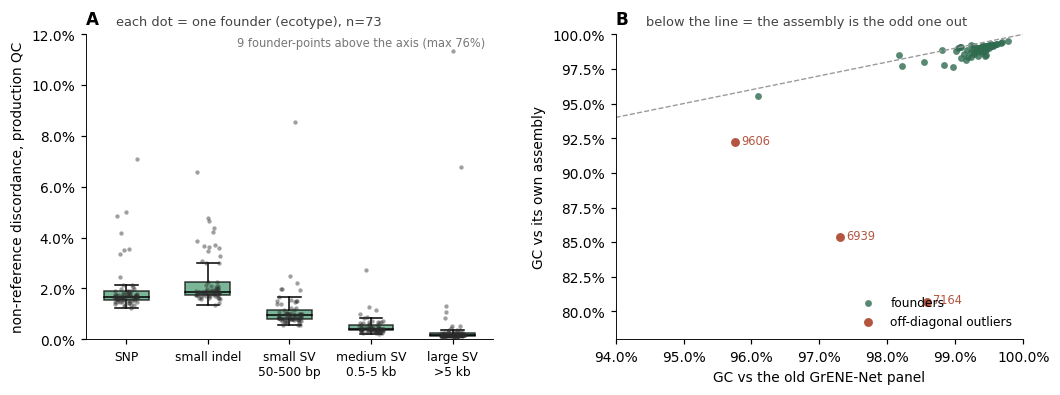

 ecotype  gn_GC  cactus_GC
    6939 0.9730     0.8536
    7164 0.9858     0.8071
    9606 0.9576     0.9221

median over the 73 founders: vs GrENE-Net 0.9937, vs its assembly 0.9895


In [4]:
K = pd.read_csv(f"{P}/preprocess_qc/output/concordance_combined.tsv", sep="\t")
K = K[(K.panel == "loo")].dropna(subset=["cactus_GC", "gn_GC"])
K = K[~K.ecotype.isin(DROPPED)]
OUTL = [7164, 6939, 9606]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(wspace=0.3))
rng = np.random.default_rng(0)
dat = [Qf.loc[Qf.size_class == c, "nRD_gq"].values for c in CLS]
bp = ax[0].boxplot(dat, labels=[CLSLAB[c] for c in CLS], widths=0.55, showfliers=False,
                   patch_artist=True, medianprops=dict(color="black"))
for p in bp["boxes"]:
    p.set_facecolor(GREEN[1]); p.set_alpha(0.75)
for i, v in enumerate(dat):
    ax[0].scatter(np.full(len(v), i+1) + rng.uniform(-.15, .15, len(v)), v, s=8,
                  color="#2b2b2b", alpha=0.45, zorder=3, linewidths=0)
YMAX = 0.12
above = int(sum((v > YMAX).sum() for v in dat))
ax[0].set_ylim(0, YMAX)
ax[0].set_ylabel("non-reference discordance, production QC")
ax[0].yaxis.set_major_formatter(PercentFormatter(1.0)); ax[0].tick_params(axis="x", labelsize=8)
ax[0].annotate(f"{above} founder-points above the axis (max {100*max(v.max() for v in dat):.0f}%)",
               (0.98, 0.96), xycoords="axes fraction", ha="right", fontsize=7.5, color="#777")
panel(ax[0], "A", "each dot = one founder (ecotype), n=73")

bad = K.ecotype.isin(OUTL)
ax[1].scatter(K.loc[~bad, "gn_GC"], K.loc[~bad, "cactus_GC"], s=20, color=GREEN[0],
              alpha=0.8, linewidths=0, label="founders")
ax[1].scatter(K.loc[bad, "gn_GC"], K.loc[bad, "cactus_GC"], s=34, color=ACCENT,
              linewidths=0, label="off-diagonal outliers")
for _, r in K[bad].iterrows():
    ax[1].annotate(int(r.ecotype), (r.gn_GC, r.cactus_GC), fontsize=7.5, color=ACCENT,
                   xytext=(4, -1), textcoords="offset points")
ax[1].plot([0.94, 1.0], [0.94, 1.0], ls="--", lw=0.9, color=GREY)
ax[1].set_xlim(0.94, 1.0); ax[1].set_ylim(0.78, 1.0)
ax[1].set_xlabel("GC vs the old GrENE-Net panel"); ax[1].set_ylabel("GC vs its own assembly")
ax[1].xaxis.set_major_formatter(PercentFormatter(1.0)); ax[1].yaxis.set_major_formatter(PercentFormatter(1.0))
ax[1].legend(frameon=False, fontsize=8, loc="lower right")
panel(ax[1], "B", "below the line = the assembly is the odd one out")
plt.savefig(f"{PLOTS}/per_founder.png", dpi=150, bbox_inches="tight"); plt.show()
print(K[bad][["ecotype", "gn_GC", "cactus_GC"]].round(4).to_string(index=False))
print(f"\nmedian over the {len(K)} founders: vs GrENE-Net {K.gn_GC.median():.4f}, "
      f"vs its assembly {K.cactus_GC.median():.4f}")

**Reading it.** Panel B resolves an open question logged in `docs/RESULTS_LOG.md`
(2026-04-29): *"are the LOO outliers similarly low against GrENE-Net (→ sample swap), or only
low against cactus (→ assembly mislabel)?"* They sit **far below the diagonal** — 96–99%
concordant against the independent GrENE-Net panel but only **81–92%** against "their own"
assembly. PanGenie agrees with an independent genotyping of the same accession and disagrees
only with the assembly it is scored against, so **the assembly is the odd one out, not the
genotyper**.

Two such founders (5772, 9947) were already known duplicate-pair members and are excluded
here. **7164, 6939 and 9606 are new candidates for the same problem** and deserve the same
check. Their presence means the accuracy numbers above are a **lower bound**.

## 4 · What it means for the candidate list

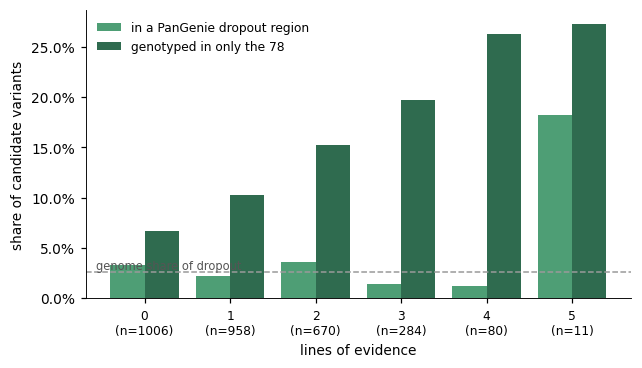

            n  frac_in_dropout  frac_78_only
n_lines                                     
0        1006            0.033         0.067
1         958            0.022         0.102
2         670            0.036         0.152
3         284            0.014         0.197
4          80            0.012         0.262
5          11            0.182         0.273


In [5]:
E = pd.read_csv(f"{P}/analysis/grenenet_selection/genes/convergence/results/evidence_matrix.csv",
                low_memory=False)
def in_drop(ch, p):
    return len(R[(R.chrom == ch) & (R.start <= p) & (R.end >= p)]) > 0
E["in_dropout"] = [in_drop(c, p) for c, p in zip(E.chrom, E.pos)]
E["sub78"] = np.isclose(E.call_rate, 78/231, atol=.002)
genome_frac = R.kb.sum()*1e3/119.7e6
gg = E.groupby("n_lines")[["in_dropout", "sub78"]].mean(); nn = E.groupby("n_lines").size()

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(gg.index - 0.2, gg.in_dropout, 0.4, color=GREEN[1], label="in a PanGenie dropout region")
ax.bar(gg.index + 0.2, gg.sub78, 0.4, color=GREEN[0], label="genotyped in only the 78")
ax.axhline(genome_frac, color=GREY, ls="--", lw=1)
ax.annotate("genome share of dropout", (0.02, genome_frac), fontsize=7.5, color="#555",
            xycoords=("axes fraction", "data"), va="bottom")
ax.set_xticks(sorted(gg.index)); ax.set_xticklabels([f"{i}\n(n={nn[i]})" for i in sorted(gg.index)], fontsize=8)
ax.set_xlabel("lines of evidence"); ax.set_ylabel("share of candidate variants")
ax.yaxis.set_major_formatter(PercentFormatter(1.0)); ax.legend(frameon=False, fontsize=8)
plt.savefig(f"{PLOTS}/candidate_exposure.png", dpi=150, bbox_inches="tight"); plt.show()
print(E.groupby("n_lines").agg(n=("sub78", "size"), frac_in_dropout=("in_dropout", "mean"),
                               frac_78_only=("sub78", "mean")).round(3).to_string())

**Reading it.** The pool as a whole is **not** enriched for dropout sequence — 2.8% of
candidates against a 2.6% genome share. The `78/231` stratum is the larger exposure: records
PanGenie skipped individually rather than regionally, **over-represented at the top of the
ranking** (27% of the 5-line variants against ~8% of a MAF-matched background).

That does not make such a candidate wrong — the projection is unbiased, and §2 says the 78
assembly genotypes are the reliable ones. It means its allele frequency carries a third of the
usual information, and that belongs in the caveats beside it.

**Accuracy does not sag around the holes**, so the two failure modes are separate problems:
non-reference discordance within 50 kb of a dropout region versus elsewhere differs by at most
0.6 points in every size class (SNP 11.1% vs 10.7%, small SV 5.2% vs 4.9%, large SV 1.1% vs
1.1%, measured pre-QC on the binned leave-one-out records). A call-rate filter is therefore
not a proxy for accuracy — it is a proxy for how much data stands behind the frequency.